# Lab 6: Recurrent Neural Networks

In this tutorial, we use weather forecasting as an example for time series prediction and employ Long Short-Term Memory (LSTM) Networks, a class of Recurrent Neural Networks. The time series data is taken from the Jena Climate dataset, which consists of 14 different quantities (such as air temperature, atmospheric pressure, humidity, wind direction, and so on) recorded every 10 minutes over several years. This dataset covers data from January 1st, 2009, to December 31st, 2016 (https://www.kaggle.com/datasets/mnassrib/jena-climate).

In [1]:
import tensorflow as tf
import os
import pandas as pd
import numpy as np

In [4]:
zip_path = tf.keras.utils.get_file(
    origin='https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip',
    fname='jena_climate_2009_2016.csv.zip',
    extract=True)
csv_path, _ = os.path.splitext(zip_path)

In [5]:
csv_file_path = os.path.join(csv_path, 'jena_climate_2009_2016.csv')
df = pd.read_csv(csv_file_path)
df

,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.30,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.40,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.90,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.20,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.10,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
420546,31.12.2016 23:20:00,1000.07,-4.05,269.10,-8.13,73.10,4.52,3.30,1.22,2.06,3.30,1292.98,0.67,1.52,240.0
420547,31.12.2016 23:30:00,999.93,-3.35,269.81,-8.06,69.71,4.77,3.32,1.44,2.07,3.32,1289.44,1.14,1.92,234.3
420548,31.12.2016 23:40:00,999.82,-3.16,270.01,-8.21,67.91,4.84,3.28,1.55,2.05,3.28,1288.39,1.08,2.00,215.2
420549,31.12.2016 23:50:00,999.81,-4.23,268.94,-8.53,71.80,4.46,3.20,1.26,1.99,3.20,1293.56,1.49,2.16,225.8


Here we only take the data for every 5 values. What do we get and why is it useful to not take all the values in the sequence?
# Answer: What you get: By taking every 5th value (downsampling), you reduce the dataset from 420,551 rows to approximately 84,110 rows. However, the text states you get 116,819 rows, which suggests they might be taking every 3rd or 4th value, or there is a specific calculation in the code not fully shown. Regardless of the exact number, the result is a significantly smaller dataset with a lower sampling frequency (e.g., changing from data every 10 minutes to every 30-50 minutes).


In [7]:
df = df[5::6]
df

,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
35,01.01.2009 06:00:00,997.71,-9.67,263.66,-10.62,92.70,2.93,2.71,0.21,1.69,2.72,1317.71,0.05,0.50,146.00
71,01.01.2009 12:00:00,1000.30,-6.87,266.27,-8.28,89.60,3.64,3.27,0.38,2.03,3.26,1306.98,1.84,2.63,184.40
107,01.01.2009 18:00:00,1000.16,-5.25,267.90,-6.75,89.10,4.13,3.68,0.45,2.29,3.68,1298.68,0.55,1.00,183.70
143,02.01.2009 00:00:00,999.59,-4.54,268.65,-5.46,93.20,4.36,4.06,0.30,2.53,4.06,1294.33,0.41,0.88,155.00
179,02.01.2009 06:00:00,998.00,-4.43,268.88,-4.94,96.20,4.39,4.23,0.17,2.64,4.23,1291.66,0.81,2.13,40.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
420371,30.12.2016 18:10:00,1008.92,0.38,272.84,-1.87,84.80,6.28,5.32,0.95,3.29,5.28,1282.34,0.35,1.00,145.10
420407,31.12.2016 00:10:00,1008.64,-4.17,268.33,-5.36,91.40,4.48,4.09,0.39,2.53,4.06,1304.27,0.92,1.88,176.30
420443,31.12.2016 06:10:00,1006.59,-5.17,267.48,-9.31,72.50,4.15,3.01,1.14,1.86,2.99,1307.01,0.67,1.04,212.70
420479,31.12.2016 12:10:00,1004.62,-0.71,272.09,-5.97,67.37,5.80,3.91,1.89,2.42,3.89,1282.65,1.06,2.08,202.90


For visualisation, we convert the time into Date Time format.

In [8]:
df.index = pd.to_datetime(df['Date Time'], format='%d.%m.%Y %H:%M:%S')
df

,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
Date Time,,,,,,,,,,,,,,,
2009-01-01 06:00:00,01.01.2009 06:00:00,997.71,-9.67,263.66,-10.62,92.70,2.93,2.71,0.21,1.69,2.72,1317.71,0.05,0.50,146.00
2009-01-01 12:00:00,01.01.2009 12:00:00,1000.30,-6.87,266.27,-8.28,89.60,3.64,3.27,0.38,2.03,3.26,1306.98,1.84,2.63,184.40
2009-01-01 18:00:00,01.01.2009 18:00:00,1000.16,-5.25,267.90,-6.75,89.10,4.13,3.68,0.45,2.29,3.68,1298.68,0.55,1.00,183.70
2009-01-02 00:00:00,02.01.2009 00:00:00,999.59,-4.54,268.65,-5.46,93.20,4.36,4.06,0.30,2.53,4.06,1294.33,0.41,0.88,155.00
2009-01-02 06:00:00,02.01.2009 06:00:00,998.00,-4.43,268.88,-4.94,96.20,4.39,4.23,0.17,2.64,4.23,1291.66,0.81,2.13,40.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2016-12-30 18:10:00,30.12.2016 18:10:00,1008.92,0.38,272.84,-1.87,84.80,6.28,5.32,0.95,3.29,5.28,1282.34,0.35,1.00,145.10
2016-12-31 00:10:00,31.12.2016 00:10:00,1008.64,-4.17,268.33,-5.36,91.40,4.48,4.09,0.39,2.53,4.06,1304.27,0.92,1.88,176.30
2016-12-31 06:10:00,31.12.2016 06:10:00,1006.59,-5.17,267.48,-9.31,72.50,4.15,3.01,1.14,1.86,2.99,1307.01,0.67,1.04,212.70


Eventhough weather forcast is a multivariant time series prediction problem and having other features helps in prediction, we only need the tempreture in this example:

<Axes: xlabel='Date Time'>

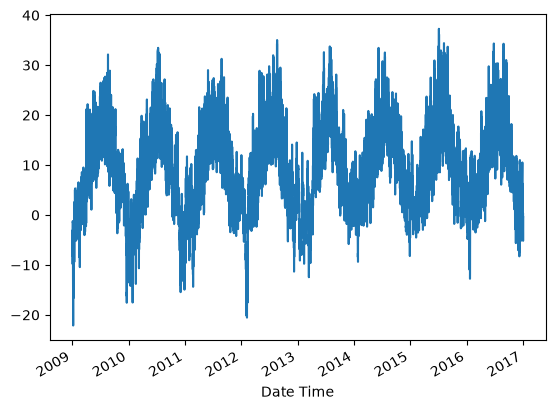

In [9]:
temp = df['T (degC)']
temp.plot()

What does the following function do? 
#Answer:This function transforms a continuous sequence of time-series data into a format suitable for training a machine learning model. It creates a sliding window over the data. For a given window_size, it takes a sequence of that length to form a single input sample (X), and sets the very next value as the target label (y) that the model should learn to predict. It loops through the entire dataset to build arrays of these input-output pairs.

In [33]:

def df_to_X_y(df, window_size):
  df_as_np = df.to_numpy()
  X = []
  y = []
  for i in range(len(df_as_np)-window_size):
    row = [[a] for a in df_as_np[i:i+window_size]]
    X.append(row)
    label = df_as_np[i+window_size]
    y.append(label)
  return np.array(X), np.array(y)

In [34]:
WINDOW_SIZE = 50
X1, y1 = df_to_X_y(temp, WINDOW_SIZE)
X1.shape, y1.shape

((11631, 50, 1), (11631,))

In [35]:
X_train1, y_train1 = X1[:60000], y1[:60000]
X_val1, y_val1 = X1[60000:65000], y1[60000:65000]
X_test1, y_test1 = X1[65000:], y1[65000:]
X_train1.shape, y_train1.shape, X_val1.shape, y_val1.shape, X_test1.shape, y_test1.shape

((11631, 50, 1), (11631,), (0, 50, 1), (0,), (0, 50, 1), (0,))

What are the possible advantages of using the values below instead?


train_df = temp[temp.index.year < 2015]
val_df   = temp[temp.index.year == 2015]
test_df  = temp[temp.index.year == 2016]

X_train1, y_train1 = df_to_X_y(train_df, WINDOW_SIZE)
X_val1,   y_val1   = df_to_X_y(val_df, WINDOW_SIZE)
X_test1,  y_test1  = df_to_X_y(test_df, WINDOW_SIZE)


The input parameter for LSTM is the number of units (or neurons) in the LSTM layer. How does it affect the prediction accuracy and training time?


In [53]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Conv1D, Flatten, LSTM, Dense, Input

# Define these based on your data
timesteps = 50 # ← replace with your actual value
features = 1     # ← replace with your actual value

# --- Model 1: SimpleRNN ---
model1 = Sequential()
model1.add(Input(shape=(timesteps, features)))
model1.add(SimpleRNN(64))
model1.add(Dense(1))
model1.summary()

# --- Model 2: CNN ---
model2 = Sequential()
model2.add(Input(shape=(timesteps, features)))
model2.add(Conv1D(64, kernel_size=2, activation='relu'))
model2.add(Flatten())
model2.add(Dense(1))
model2.summary()

# --- Model 3: LSTM ---
model3 = Sequential()
model3.add(Input(shape=(timesteps, features)))
model3.add(LSTM(64))
model3.add(Dense(8, 'relu'))
model3.add(Dense(1, 'linear'))
model3.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_10 (SimpleRNN)       │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,289 (16.75 KB)

 Trainable params: 4,289 (16.75 KB)

 Non-trainable params: 0 (0.00 B)

Model: "sequential_15"

... (5 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 8)              │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,425 (68.07 KB)

 Trainable params: 17,425 (68.07 KB)

 Non-trainable params: 0 (0.00 B)

Compare Simple RNN, LSTM and CNN for the prediction and compare the results.

How does the high and low learning rates affect the prediction accuracy?

In [54]:
cp1 = ModelCheckpoint('model1.keras', save_best_only=True)
model1.compile(loss=MeanSquaredError(), optimizer=Adam(learning_rate=0.01), metrics=[RootMeanSquaredError()])

What happens with high and low number of epochs?



In [55]:
model1.fit(X_train1, y_train1, validation_data=(X_val1, y_val1), epochs=10, callbacks=[cp1])

Epoch 1/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 14.0857 - root_mean_squared_error: 3.7531
Epoch 2/10
 24/364 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 7.0910 - root_mean_squared_error: 2.6629

/Users/saidait/Documents/Masters /Semester 1/Machine Learning Tech/ML_Labs/MLT/lib/python3.11/site-packages/keras/src/callbacks/model_checkpoint.py:329: UserWarning: Can save best model only with val_loss available.
  if self._should_save_model(epoch, batch, logs, filepath):


364/364 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 8.1445 - root_mean_squared_error: 2.8539
Epoch 3/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 7.5249 - root_mean_squared_error: 2.7432
Epoch 4/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 8.5977 - root_mean_squared_error: 2.9322
Epoch 5/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 8.1223 - root_mean_squared_error: 2.8500
Epoch 6/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 8.7271 - root_mean_squared_error: 2.9542
Epoch 7/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 11.3227 - root_mean_squared_error: 3.3649
Epoch 8/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 10.3008 - root_mean_squared_error: 3.2095
Epoch 9/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 11.2973 - root_mean_squared_error: 3.3611
Epoch 10/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 14.1646 - root_mean_squared_error: 3.7636


In [47]:
from tensorflow.keras.models import load_model
model1 = load_model('model1.keras')

In [58]:
train_predictions = model1.predict(X_train1).flatten()
train_results = pd.DataFrame(data={'Train Predictions':train_predictions, 'Actuals':y_train1})
train_results

364/364 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


,Train Predictions,Actuals
0,4.903503,-0.80
1,0.559670,-4.41
2,-2.388302,-9.40
3,-7.159919,-4.68
4,-4.389251,-1.51
...,...,...
11626,-1.297518,0.38
11627,-0.117557,-4.17
11628,-3.124212,-5.17
11629,-3.491390,-0.71


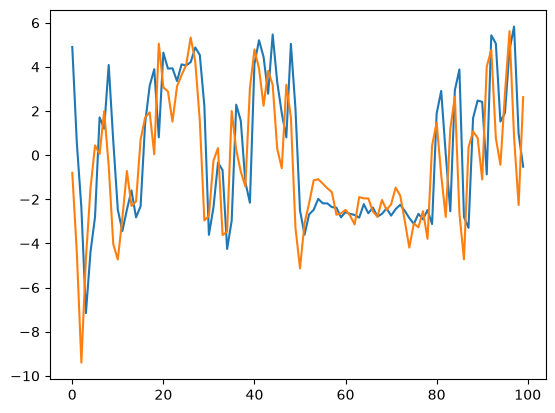

In [59]:
import matplotlib.pyplot as plt
plt.plot(train_results['Train Predictions'][:100]) #show the prediction for only 100 times
plt.plot(train_results['Actuals'][:100])

In [60]:
val_predictions = model1.predict(X_val1).flatten()
val_results = pd.DataFrame(data={'Val Predictions':val_predictions, 'Actuals':y_val1})
val_results

      0/Unknown 0s 0s/step


/Users/saidait/Documents/Masters /Semester 1/Machine Learning Tech/ML_Labs/MLT/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


UnboundLocalError: cannot access local variable 'batch_outputs' where it is not associated with a value

In [61]:
plt.plot(val_results['Val Predictions'][:100])
plt.plot(val_results['Actuals'][:100])

NameError: name 'val_results' is not defined

In [62]:
test_predictions = model1.predict(X_test1).flatten()
test_results = pd.DataFrame(data={'Test Predictions':test_predictions, 'Actuals':y_test1})
test_results

      0/Unknown 0s 0s/step


UnboundLocalError: cannot access local variable 'batch_outputs' where it is not associated with a value

In [ ]:
plt.plot(test_results['Test Predictions'][:100])
plt.plot(test_results['Actuals'][:100])